# Cross-dataset MSN integration — HD (Handsaker) + NucSeq + SlideTags — joint scVI/scANVI

**Strategy:** concatenate all three datasets and train **one** scVI model (then scANVI on top) on all of them together — no reference/query split, every dataset gets equal weight.
This replaces the earlier scArches notebook (`01_integrate_HD_NucSeq_SlideTags_scArches.ipynb`), where HD was the reference and NucSeq+SlideTags were mapped on by surgery. Surgery only learns new batch embeddings for the query, so it cannot absorb a technology the reference never saw (SlideTags).

**Integration design (one model):**
`scVI(batch_key = "batch", categorical_covariate_keys = ["sex"])`, where `batch` = `<dataset>__<technical library unit>`.

| dataset | `batch` unit | pooling design (MSN cells) |
|---|---|---|
| HD | `reaction` (47) | Village pools: ~17 donors per reaction, each donor in ~8 reactions → donor **crossed** with batch |
| NucSeq | `library` (16) | ~16 donors (XDP + control) multiplexed per library, each donor in 4–8 libraries → donor **crossed** with batch |
| SlideTags | `library_id` (51) | one donor per library (one puck/sort), 3–8 libraries per donor → batch **nested** in donor |

Why only these covariates:
- **`dataset` is not added**: every `batch` level sits inside exactly one dataset, so the batch embedding already carries the dataset/technology effect.
- **`donor` is not added**: in HD/NucSeq donor is biology (and crossed with batch, so it stays in the latent space); in SlideTags it is aliased with `library_id` anyway.
- **SlideTags `Sorted` (NeUN+/Unsorted) is not added**: it is constant within each `library_id`, so the batch already absorbs it.
- SlideTags `library` (`SI-TT-H1`, …) is **not unique** — the same index is reused across sequencing runs — so `library_id` (run + index) is the batch unit.

Consequence to keep in mind: in SlideTags, correcting `library_id` also removes donor-to-donor differences (and, if both conditions are integrated, part of the disease signal) from the latent space. Fine for a latent used for cell-type mapping/clustering — **do not run DE on the latent**; DE stays on counts (nebula, donor as random effect).

**Counts:** raw counts are read from `layers["counts"]` (falls back to `X`). SlideTags' `X` is **empty** in the current h5ad — the old notebook deleted the layers and trained on `X`, i.e. SlideTags entered the model as all-zero cells (that is why it collapsed onto Matrix_D2).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import re
import itertools

import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
from anndata.io import sparse_dataset
import scvi
import seaborn as sns
import matplotlib.pyplot as plt

from utils import label_mapping_utils as lmu

scvi.settings.seed = 42
print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")

Seed set to 42


scvi-tools: 1.4.0.post1, scanpy: 1.11.5, anndata: 0.12.6


/tmp/ipykernel_621896/3154600971.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")
/tmp/ipykernel_621896/3154600971.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")


## 1 · Config

In [ ]:
RAW_PATHS = {
    "HD":        "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad",
    "nucseq":    "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad",
    "slidetags": "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad",
}

CELL_TYPE_COL   = "Group_name"   # coarse MapMyCells label -- used ONLY to choose which cells to integrate (Section 2)
TRAIN_LABEL_COL = "ct_for_deg"   # finer, project-curated subtype -- used for scANVI labels + validation

# ── Subsampling (quick runs) ──
# None = full data. A float (e.g. 0.1) keeps that fraction of cells, sampled WITHIN each batch,
# so every library keeps the same share and dataset/library proportions are preserved.
# Applied last in Section 5 (after all filters). Outputs go to a separate RUN_NAME folder,
# so a subsampled run never overwrites the full-data model.
SUBSAMPLE_FRAC = None
SUBSAMPLE_SEED = 42

# Optional: restrict integration to one disease status and/or one sex (None = keep everything).
FILTER_STATUS = None   # "Diseased" / "Healthy" / None
FILTER_SEX    = None         # "Male" / "Female" / None

RAW_CONDITION_COL = {"HD": "Status", "nucseq": "condition", "slidetags": "condition"}
CONDITION_MAP = {
    "HD":        {"Case": "Diseased", "Control": "Healthy"},
    "nucseq":    {"XDP": "Diseased", "Control": "Healthy"},
    "slidetags": {"diseased": "Diseased", "healthy": "Healthy"},
}

# Technical library unit per dataset -> scVI batch (see design table above)
BATCH_COL_MAP = {
    "HD":        "reaction",     # Village pooled reaction (many donors)
    "nucseq":    "library",      # multiplexed 10x library (many donors)
    "slidetags": "library_id",   # sequencing run + index (one donor); `library` alone is not unique
}

DONOR_COL_MAP = {"HD": "DONOR", "nucseq": "donor_id", "slidetags": "donor_id"}

RAW_SEX_COL = {"HD": "Sex", "nucseq": "sex", "slidetags": "sex"}
SEX_MAP = {
    "HD":        {"Male": "Male", "Female": "Female"},
    "nucseq":    {"M": "Male", "F": "Female"},
    "slidetags": {"male": "Male", "female": "Female"},
}

USE_SCANVI     = True        # False = plain unsupervised scVI, no classifier / predicted labels
LABELS_KEY     = "celltype_scanvi"
UNLABELLED     = "Unknown"
MIN_BATCH_SIZE = 100         # drop batches with fewer cells (batch effect can't be estimated)

N_TOP_GENES         = 3000
SCVI_MAX_EPOCHS     = 50     # early stopping on
SCANVI_MAX_EPOCHS   = 20
N_SAMPLES_PER_LABEL = 100
BATCH_SIZE          = 512
CONF_THRESHOLD      = 0.8

# scArches-compatible architecture, so new samples can later be mapped onto this joint model by surgery
SCVI_PARAMS = dict(
    use_layer_norm="both",
    use_batch_norm="none",
    encode_covariates=True,
    dropout_rate=0.2,
    n_layers=2,
    n_latent=30,
    gene_likelihood="nb",
)

RUN_NAME = "full" if SUBSAMPLE_FRAC is None else f"subsample_{SUBSAMPLE_FRAC}"
OUT_DIR  = f"/home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/{RUN_NAME}"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"RUN_NAME={RUN_NAME} -> {OUT_DIR}")

RUN_NAME=full -> /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/full


## 2 · Choose cells and labels

Two filters, applied **identically to all three datasets** (no per-dataset special-casing, so whatever population exists on one side can exist on the other):
1. `CELL_TYPES_TO_INTEGRATE` — coarse `Group_name` (MapMyCells).
2. `KEEP_LABELS` — `ct_for_deg` values kept inside those groups (drops non-MSN contaminants and stray interneurons). Labels that exist in only one dataset are fine here.

`SCANVI_LABELS` — the `ct_for_deg` classes the scANVI classifier is trained on. Every other kept label (dataset-specific QC calls like `-Low_quality`, `TAFA1`, `-Mito_cluster_patch`, …) is set to `Unknown`, so it is placed by the unsupervised part of the model and its prediction is informative rather than forced.

`LABEL_HOLDOUT_DATASETS` — datasets whose labels are all masked (`Unknown`) during scANVI training. Their predictions vs. their own `ct_for_deg` are then an unbiased transfer test (Section 7). E.g. `["slidetags"]`.

In [ ]:
CELL_TYPES_TO_INTEGRATE = [
    "STRd D1 Matrix MSN",
    "STRd D1 Striosome MSN",
    "STRv D1 MSN",

    "STRd D2 Matrix MSN",
    "STRd D2 Striosome MSN",
    "STRv D2 MSN",

    "STRd D2 StrioMat Hybrid MSN",
    "STR D1D2 Hybrid MSN",
    "STRv D1 NUDAP MSN",
]

KEEP_LABELS = [
    "Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "eMSN_StrioMat",   # shared by all three
    "-Low_quality",                                                      # all three, dataset-specific QC calls
    "-Phase_D", "-fake_phase_D",                                         # HD only
    "-TAFA1",                                                            # NucSeq only
    "TAFA1", "-Mito_cluster_patch",                                      # SlideTags only
    # dropped: "non-MSN", "-Non_neuron_Neun_Pos_Lib", "-Unassigned", stray GABA interneurons, "eMSN_D1D2" (1 cell)
]

SCANVI_LABELS = KEEP_LABELS #["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "eMSN_StrioMat", "-Phase_D"]

LABEL_HOLDOUT_DATASETS = []   # e.g. ["slidetags"]

assert set(SCANVI_LABELS) <= set(KEEP_LABELS)

In [4]:
_backed = {name: sc.read_h5ad(p, backed="r") for name, p in RAW_PATHS.items()}

# Group_name counts, and what KEEP_LABELS keeps/drops inside the chosen groups
for name, a in _backed.items():
    in_groups = a.obs[CELL_TYPE_COL].isin(CELL_TYPES_TO_INTEGRATE)
    print(f"--- {name} ({a.n_obs} cells total, {in_groups.sum()} in chosen groups) ---")
    missing = [ct for ct in CELL_TYPES_TO_INTEGRATE if (a.obs[CELL_TYPE_COL] == ct).sum() == 0]
    if missing:
        print(f"  WARNING: not present in {name}: {missing}")
    lab = a.obs.loc[in_groups, TRAIN_LABEL_COL].astype(str)
    print(lab.value_counts().to_frame("n").assign(kept=lambda d: d.index.isin(KEEP_LABELS)).to_string())
    print()

--- HD (581273 cells total, 170892 in chosen groups) ---
                        n   kept
ct_for_deg                      
Matrix_D1           71001   True
Matrix_D2           62107   True
Patch_D1            19034   True
Patch_D2            14060   True
-Low_quality         2762   True
-Phase_D             1505   True
eMSN_StrioMat         279   True
-fake_phase_D         116   True
non-MSN                24  False
ACx MEIS2 GABA          2  False
STR SST-CHODL GABA      1  False
VIP GABA                1  False

--- nucseq (231080 cells total, 40311 in chosen groups) ---
                   n   kept
ct_for_deg                 
Matrix_D2      11742   True
Matrix_D1      11037   True
-Low_quality    9245   True
Patch_D1        4098   True
Patch_D2        3162   True
-TAFA1           899   True
eMSN_StrioMat     95   True
non-MSN           32  False
eMSN_D1D2          1  False

--- slidetags (742896 cells total, 127926 in chosen groups) ---
                              n   kept
ct_for_d

## 3 · Gene overlap across the three datasets

All three datasets use **Ensembl gene IDs as `var_names`**, so overlap is computed on `var_names`, not on the `gene_symbol` column — HD's `gene_symbol` annotation is older, so symbol-based overlap with HD undercounts by ~10k genes even where the Ensembl IDs match.

In [5]:
var_names_sets = {name: set(a.var_names) for name, a in _backed.items()}

for name, a in _backed.items():
    is_ensembl = a.var_names.str.match(r"^ENSG\d+").mean()
    print(f"{name}: example={list(a.var_names[:2])}, {is_ensembl:.0%} look like Ensembl IDs (ENSG...)")
    assert is_ensembl > 0.95, f"{name}: var_names doesn't look like Ensembl IDs -- check before trusting the overlap below"

print("\nPairwise overlap (Ensembl IDs, i.e. var_names):")
for a, b in itertools.combinations(var_names_sets, 2):
    print(f"  {a} ({len(var_names_sets[a])}) vs {b} ({len(var_names_sets[b])}): {len(var_names_sets[a] & var_names_sets[b])}")

COMMON_GENES = sorted(set.intersection(*var_names_sets.values()))
print(f"\nGenes shared by all {len(var_names_sets)} datasets (by Ensembl ID): {len(COMMON_GENES)}")

HD: example=['ENSG00000121410', 'ENSG00000268895'], 100% look like Ensembl IDs (ENSG...)
nucseq: example=['ENSG00000223972', 'ENSG00000243485'], 96% look like Ensembl IDs (ENSG...)
slidetags: example=['ENSG00000290825', 'ENSG00000243485'], 100% look like Ensembl IDs (ENSG...)

Pairwise overlap (Ensembl IDs, i.e. var_names):
  HD (36943) vs nucseq (38601): 30692
  HD (36943) vs slidetags (37588): 31793
  nucseq (38601) vs slidetags (37588): 35694

Genes shared by all 3 datasets (by Ensembl ID): 30589


In [6]:
# Symbol-based overlap, only to show the annotation-vintage caveat above -- DO NOT use this to subset
symbol_sets = {name: set(a.var["gene_symbol"].astype(str)) for name, a in _backed.items()}
print("Pairwise overlap (gene_symbol -- comparison only):")
for a, b in itertools.combinations(symbol_sets, 2):
    print(f"  {a} vs {b}: {len(symbol_sets[a] & symbol_sets[b])}")

Pairwise overlap (gene_symbol -- comparison only):
  HD vs nucseq: 20738
  HD vs slidetags: 20988
  nucseq vs slidetags: 35171


## 4 · Donor ID harmonization

NucSeq and SlideTags are two modalities of the same XDP cohort, and several donors were profiled in **both**. Their IDs are written inconsistently (`SCF-22-057` vs `SCF_22-057CM`: separator and multiplexing-pool suffix), so they are normalized. HD is a separate cohort with an already-consistent `S#####` scheme (normalizing it would mangle it), so it is only checked for non-collision.

`donor_id_unified` is metadata only (plots, per-donor stats) — **not** a model covariate (see design above).

In [7]:
def normalize_donor_id(x):
    # uppercase, unify separators, strip multiplexing-pool suffixes like 'CM', 'CF', 'CM2'
    x = str(x).strip().upper()
    if x in ("NAN", "UNASSIGNED", "NA", ""):
        return None
    x = x.replace("_", "-")
    m = re.match(r"^([A-Z]+)-?(\d+)-?(\d+)", x)
    if m:
        prefix, a, b = m.groups()
        return f"{prefix}-{a}-{b}"
    return x

NORMALIZE_DONOR_IDS = {"nucseq", "slidetags"}

donor_id_unified = {
    name: (a.obs[DONOR_COL_MAP[name]].astype(str).map(normalize_donor_id) if name in NORMALIZE_DONOR_IDS
           else a.obs[DONOR_COL_MAP[name]].astype(str))
    for name, a in _backed.items()
}

shared_nucseq_slidetags = set(donor_id_unified["nucseq"].dropna()) & set(donor_id_unified["slidetags"].dropna())
print(f"nucseq donors: {donor_id_unified['nucseq'].nunique()}, slidetags donors: {donor_id_unified['slidetags'].nunique()}")
print(f"Donors shared between nucseq and slidetags: {len(shared_nucseq_slidetags)}")
print(sorted(shared_nucseq_slidetags))

xdp_ids = set(donor_id_unified["nucseq"].dropna()) | set(donor_id_unified["slidetags"].dropna())
assert not (set(donor_id_unified["HD"].dropna()) & xdp_ids), "HD donor IDs collide with the SCF/PCMC namespace"

nucseq donors: 47, slidetags donors: 12
Donors shared between nucseq and slidetags: 12
['SCF-18-003', 'SCF-18-006', 'SCF-19-014', 'SCF-20-024', 'SCF-20-025', 'SCF-20-026', 'SCF-21-032', 'SCF-22-043', 'SCF-22-057', 'SCF-22-065', 'SCF-23-068', 'SCF-23-075']


## 5 · Load each dataset: chosen cells × common genes, raw counts, harmonized metadata

Counts are read straight from the h5ad (`layers/counts`, falling back to `X`) for the selected rows only — never from `X` blindly, since SlideTags' `X` is empty.
Order of operations per dataset: cell filter → sex harmonization → `FILTER_STATUS`/`FILTER_SEX` → drop batches < `MIN_BATCH_SIZE` → `SUBSAMPLE_FRAC`.

In [8]:
def read_counts(name, rows, cols):
    # raw counts for the given row/column positions, as float32 CSR
    with h5py.File(RAW_PATHS[name], "r") as f:
        key = "layers/counts" if "layers/counts" in f else "X"
        X = sparse_dataset(f[key])[rows][:, cols]
    assert X.nnz > 0, f"{name}: '{key}' is empty for the selected cells"
    assert np.all(X.data[:100_000] == np.round(X.data[:100_000])), f"{name}: '{key}' is not raw integer counts"
    print(f"  counts read from '{key}'")
    return X.astype(np.float32)


def load_and_prepare(name):
    print(name)
    b = _backed[name]

    keep = (b.obs[CELL_TYPE_COL].isin(CELL_TYPES_TO_INTEGRATE)
            & b.obs[TRAIN_LABEL_COL].astype(str).isin(KEEP_LABELS)).to_numpy()
    rows = np.flatnonzero(keep)
    cols = b.var_names.get_indexer(COMMON_GENES)

    a = anndata.AnnData(
        X=read_counts(name, rows, cols),
        obs=b.obs.iloc[rows].copy(),
        var=b.var.iloc[cols][["gene_symbol"]].copy(),
    )
    a.layers["counts"] = a.X.copy()

    # SlideTags obsm["spatial"] = cross-puck ALIGNED coords, stored as obs columns (NaN elsewhere)
    # because concat(join="inner") keeps only obs columns present in every dataset
    a.obs["spatial_x"] = b.obsm["spatial"][rows, 0] if name == "slidetags" else np.nan
    a.obs["spatial_y"] = b.obsm["spatial"][rows, 1] if name == "slidetags" else np.nan
    if name == "HD":
        a.obs["village"] = a.obs["reaction"].astype(str).str.split("_").str[0]

    # harmonized metadata
    a.obs["dataset"] = name
    a.obs["donor_id_unified"] = donor_id_unified[name].iloc[rows].values
    assert a.obs[BATCH_COL_MAP[name]].notna().all(), f"{name}: missing values in batch column {BATCH_COL_MAP[name]}"
    a.obs["batch"] = name + "__" + a.obs[BATCH_COL_MAP[name]].astype(str)
    a.obs[CELL_TYPE_COL] = a.obs[CELL_TYPE_COL].astype(str)
    a.obs[TRAIN_LABEL_COL] = a.obs[TRAIN_LABEL_COL].astype(str)

    # .str.strip(): SlideTags has a "diseased " (trailing space) category
    a.obs["status"] = a.obs[RAW_CONDITION_COL[name]].astype(str).str.strip().map(CONDITION_MAP[name])
    assert a.obs["status"].notna().all(), f"{name}: unmapped condition value(s)"
    a.obs["is_diseased"] = a.obs["status"] == "Diseased"

    # sex must stay within {"Male","Female"} -- cells with unmapped/missing sex are dropped
    a.obs["sex"] = a.obs[RAW_SEX_COL[name]].astype(str).str.strip().map(SEX_MAP[name])
    if a.obs["sex"].isna().any():
        print(f"  dropping {a.obs['sex'].isna().sum()} cells with unknown/missing sex")
    a = a[a.obs["sex"].notna()].copy()

    if FILTER_STATUS is not None:
        a = a[a.obs["status"] == FILTER_STATUS].copy()
        print(f"  FILTER_STATUS='{FILTER_STATUS}': kept {a.n_obs} cells")
    if FILTER_SEX is not None:
        a = a[a.obs["sex"] == FILTER_SEX].copy()
        print(f"  FILTER_SEX='{FILTER_SEX}': kept {a.n_obs} cells")

    batch_counts = a.obs["batch"].value_counts()
    small = batch_counts[batch_counts < MIN_BATCH_SIZE]
    if len(small):
        print(f"  dropping {len(small)} batch(es) with < {MIN_BATCH_SIZE} cells: {small.to_dict()}")
    a = a[~a.obs["batch"].isin(small.index)].copy()

    if SUBSAMPLE_FRAC is not None:
        keep_idx = (a.obs.groupby("batch", observed=True, group_keys=False)
                     .sample(frac=SUBSAMPLE_FRAC, random_state=SUBSAMPLE_SEED).index)
        a = a[keep_idx].copy()
        print(f"  SUBSAMPLE_FRAC={SUBSAMPLE_FRAC} (within batch): {a.n_obs} cells")

    print(f"  -> {a.shape}")
    return a


adatas = {name: load_and_prepare(name) for name in RAW_PATHS}
del _backed

HD
  counts read from 'layers/counts'
  FILTER_STATUS='Diseased': kept 45224 cells
  -> (45224, 30589)
nucseq
  counts read from 'layers/counts'
  FILTER_STATUS='Diseased': kept 15517 cells
  -> (15517, 30589)
slidetags
  counts read from 'layers/counts'
  FILTER_STATUS='Diseased': kept 72648 cells
  -> (72648, 30589)


In [9]:
# Pooling design per dataset, computed on the cells actually used:
# crossed = each batch holds several donors (donor effect stays in the latent),
# nested  = one donor per batch (batch correction also removes donor effects)
design = []
for name, a in adatas.items():
    o = a.obs
    donors_per_batch = o.groupby("batch", observed=True)["donor_id_unified"].nunique()
    batches_per_donor = o.groupby("donor_id_unified", observed=True)["batch"].nunique()
    cells_per_batch = o["batch"].value_counts()
    design.append(dict(
        dataset=name, batch_col=BATCH_COL_MAP[name], n_cells=a.n_obs,
        n_batches=o["batch"].nunique(), n_donors=o["donor_id_unified"].nunique(),
        donors_per_batch_median=donors_per_batch.median(), batches_per_donor_median=batches_per_donor.median(),
        cells_per_batch_min=cells_per_batch.min(), cells_per_batch_median=cells_per_batch.median(),
        design="nested" if donors_per_batch.max() == 1 else "crossed",
    ))
pd.DataFrame(design).set_index("dataset")

,batch_col,n_cells,n_batches,n_donors,donors_per_batch_median,batches_per_donor_median,cells_per_batch_min,cells_per_batch_median,design
dataset,,,,,,,,,
HD,reaction,45224,47,50,8.0,8.0,305,1065.0,crossed
nucseq,library,15517,16,30,11.5,4.0,420,1008.5,crossed
slidetags,library_id,72648,38,8,1.0,4.0,154,988.5,nested


In [10]:
for name, a in adatas.items():
    print(f"--- {name} ---")
    print(pd.crosstab(a.obs[TRAIN_LABEL_COL], a.obs["sex"]).assign(total=lambda d: d.sum(axis=1)).to_string())
    print()

--- HD ---
sex            Female   Male  total
ct_for_deg                         
-Low_quality      376    376    752
-Phase_D          708    694   1402
-fake_phase_D      73      0     73
Matrix_D1       10506  10724  21230
Matrix_D2        7053   7196  14249
Patch_D1         2054   2656   4710
Patch_D2         1166   1642   2808

--- nucseq ---
sex            Female  Male  total
ct_for_deg                        
-Low_quality      156  3291   3447
-TAFA1             11   568    579
Matrix_D1         107  3717   3824
Matrix_D2         106  4170   4276
Patch_D1           38  1899   1937
Patch_D2           27  1371   1398
eMSN_StrioMat       0    56     56

--- slidetags ---
sex                   Male  total
ct_for_deg                       
-Low_quality         10942  10942
-Mito_cluster_patch   1207   1207
Matrix_D1            20974  20974
Matrix_D2            23140  23140
Patch_D1              6592   6592
Patch_D2              4610   4610
TAFA1                 5183   5183



## 6 · Joint scVI → scANVI on all three datasets

HVGs are selected with `batch_key="dataset"` (seurat_v3 per dataset, ranked by how many datasets call a gene variable), so no single technology dominates the gene set. Using the ~100 library-level batches instead makes the per-batch loess fits fragile on small libraries.

In [11]:
adata = anndata.concat(adatas, join="inner", index_unique="-", merge="first")  # merge="first": keep var gene_symbol
for col in ["dataset", "batch", "sex", "status", "donor_id_unified", TRAIN_LABEL_COL, CELL_TYPE_COL]:
    adata.obs[col] = adata.obs[col].astype(str).astype("category")

# scANVI labels: SCANVI_LABELS from non-held-out datasets, everything else Unknown
use_label = adata.obs[TRAIN_LABEL_COL].isin(SCANVI_LABELS) & ~adata.obs["dataset"].isin(LABEL_HOLDOUT_DATASETS)
adata.obs[LABELS_KEY] = np.where(use_label, adata.obs[TRAIN_LABEL_COL].astype(str), UNLABELLED)

adata.layers["log1p_norm"] = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4, layer="log1p_norm")
sc.pp.log1p(adata, layer="log1p_norm")

sc.pp.highly_variable_genes(adata, n_top_genes=N_TOP_GENES, flavor="seurat_v3", layer="counts", batch_key="dataset")
adata = adata[:, adata.var["highly_variable"]].copy()

print(adata)
print(adata.obs["dataset"].value_counts())
print(pd.crosstab(adata.obs[LABELS_KEY], adata.obs["dataset"]))

AnnData object with n_obs × n_vars = 133389 × 3000
    obs: 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.1_all_cells', 'leiden_0.5_all_cells', 'leiden_0.07_all_cells', 'ct_for_deg', 'is_neuron', 'spatial_x', 'spatial_y', 'dataset', 'donor_id_unified', 'batch', 'status', 'is_diseased', 'sex', 'celltype_scanvi'
    var: '

In [12]:
# sex is only a covariate if both sexes are present (FILTER_SEX or an all-male subset makes it constant)
covariate_keys = ["sex"] if adata.obs["sex"].nunique() > 1 else None
print(f"batch_key='batch' ({adata.obs['batch'].nunique()} levels), categorical_covariate_keys={covariate_keys}")

scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="batch", categorical_covariate_keys=covariate_keys)
scvi_model = scvi.model.SCVI(adata, **SCVI_PARAMS)
scvi_model.train(
    max_epochs=SCVI_MAX_EPOCHS,
    early_stopping=True,
    batch_size=BATCH_SIZE,
    datasplitter_kwargs={"num_workers": 16},
)

batch_key='batch' (101 levels), categorical_covariate_keys=['sex']


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/50 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=50` reached.


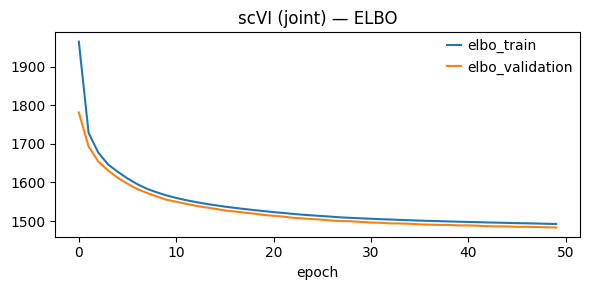

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
scvi_model.history["elbo_train"].plot(ax=ax, label="train")
scvi_model.history["elbo_validation"].plot(ax=ax, label="validation")
ax.set(title="scVI (joint) — ELBO"); ax.legend()
plt.tight_layout(); plt.show()

INFO     Training for 20 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


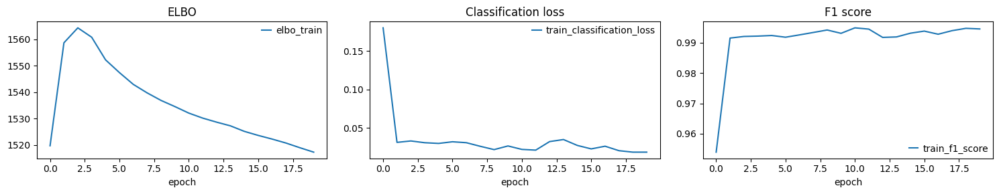

In [14]:
if USE_SCANVI:
    model = scvi.model.SCANVI.from_scvi_model(scvi_model, unlabeled_category=UNLABELLED, labels_key=LABELS_KEY)
    model.train(
        max_epochs=SCANVI_MAX_EPOCHS,
        n_samples_per_label=N_SAMPLES_PER_LABEL,
        batch_size=BATCH_SIZE,
        datasplitter_kwargs={"num_workers": 16},
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 3))
    model.history["elbo_train"].plot(ax=axes[0], title="ELBO")
    model.history["train_classification_loss"].plot(ax=axes[1], title="Classification loss")
    model.history["train_f1_score"].plot(ax=axes[2], title="F1 score")
    plt.tight_layout(); plt.show()
else:
    model = scvi_model
    print("USE_SCANVI=False: using the unsupervised scVI model.")

LATENT_KEY = "X_scANVI" if USE_SCANVI else "X_scVI"
adata.obsm["X_scVI"] = scvi_model.get_latent_representation()
adata.obsm[LATENT_KEY] = model.get_latent_representation()

sc.pp.neighbors(adata, use_rep=LATENT_KEY)
sc.tl.umap(adata, min_dist=0.3)

In [15]:
if USE_SCANVI:
    adata.obs["predicted_scanvi"] = model.predict()
    adata.obs["prediction_confidence"] = model.predict(soft=True).max(axis=1).values
    adata.obs["predicted_filtered"] = adata.obs["predicted_scanvi"].astype(str)
    adata.obs.loc[adata.obs["prediction_confidence"] < CONF_THRESHOLD, "predicted_filtered"] = "Low_confidence"

    n_high = (adata.obs["prediction_confidence"] >= CONF_THRESHOLD).sum()
    print(f"High confidence (>= {CONF_THRESHOLD}): {n_high}/{adata.n_obs} ({100 * n_high / adata.n_obs:.1f}%)")
    print(pd.crosstab(adata.obs["predicted_scanvi"], adata.obs["dataset"]))

High confidence (>= 0.8): 128914/133389 (96.6%)
dataset              HD  nucseq  slidetags
predicted_scanvi                          
-Phase_D           2109     465       6854
Matrix_D1         20300    4736      23240
Matrix_D2         14249    5162      26134
Patch_D1           5395    2876       9060
Patch_D2           3157    2177       7099
eMSN_StrioMat        14     101        261


In [16]:
model.save(f"{OUT_DIR}/model/", overwrite=True)
adata.write(f"{OUT_DIR}/adata_joint_hvg.h5ad")
print(f"Model and adata saved to {OUT_DIR}")

... storing 'celltype_scanvi' as categorical
... storing 'predicted_scanvi' as categorical
... storing 'predicted_filtered' as categorical


Model and adata saved to /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/full


## 7 · Validate predictions against each dataset's own `ct_for_deg`

Rows = own label, columns = scANVI prediction (row-normalized). Accuracy is computed only on rows whose own label is in `SCANVI_LABELS`.
- Datasets in `LABEL_HOLDOUT_DATASETS`: their labels were never seen → **unbiased** transfer accuracy.
- Other datasets: those labels were used for training → accuracy is optimistic (self-prediction).
- Rows for labels outside `SCANVI_LABELS` (e.g. `TAFA1`, `-Low_quality`) show where those populations land.

=== HD [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.9255 (44399 cells) ===


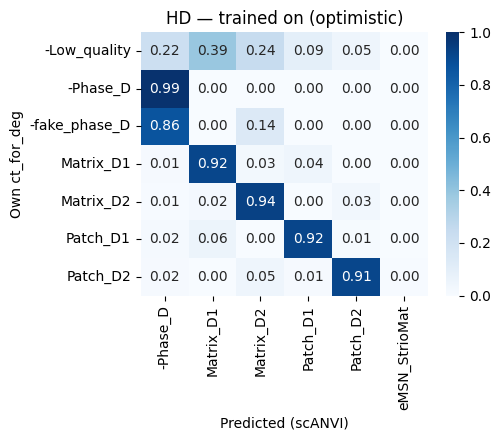

=== nucseq [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.9299 (11491 cells) ===


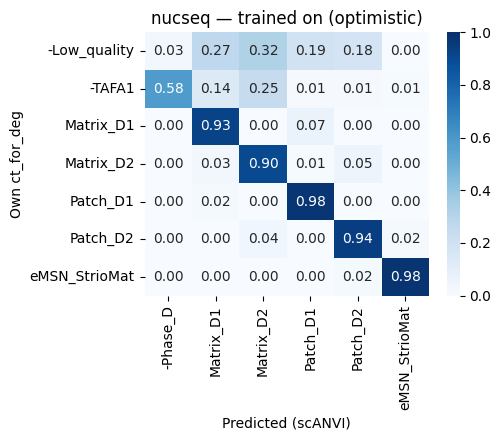

=== slidetags [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.9200 (55316 cells) ===


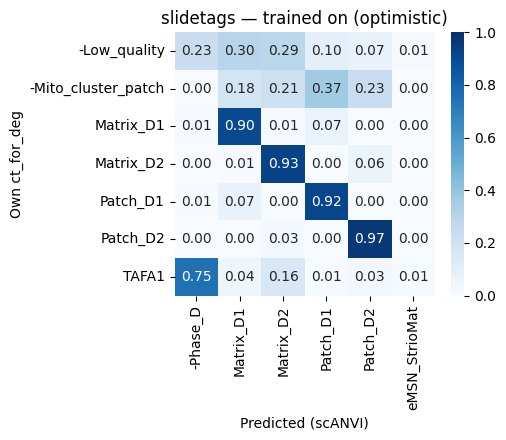

In [17]:
if USE_SCANVI:
    for name in adata.obs["dataset"].cat.categories:
        o = adata.obs[adata.obs["dataset"] == name]
        own, pred = o[TRAIN_LABEL_COL].astype(str), o["predicted_scanvi"].astype(str)
        scored = own.isin(SCANVI_LABELS)
        kind = "held out (unbiased)" if name in LABEL_HOLDOUT_DATASETS else "trained on (optimistic)"
        print(f"=== {name} [{kind}]: accuracy on SCANVI_LABELS = {(own[scored] == pred[scored]).mean():.4f} ({scored.sum()} cells) ===")

        ct = pd.crosstab(own, pred, normalize="index")
        plt.figure(figsize=(1 + 0.7 * ct.shape[1], 1 + 0.5 * ct.shape[0]))
        sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
        plt.xlabel("Predicted (scANVI)"); plt.ylabel(f"Own {TRAIN_LABEL_COL}")
        plt.title(f"{name} — {kind}")
        plt.tight_layout(); plt.show()

## 8 · Joint visualization

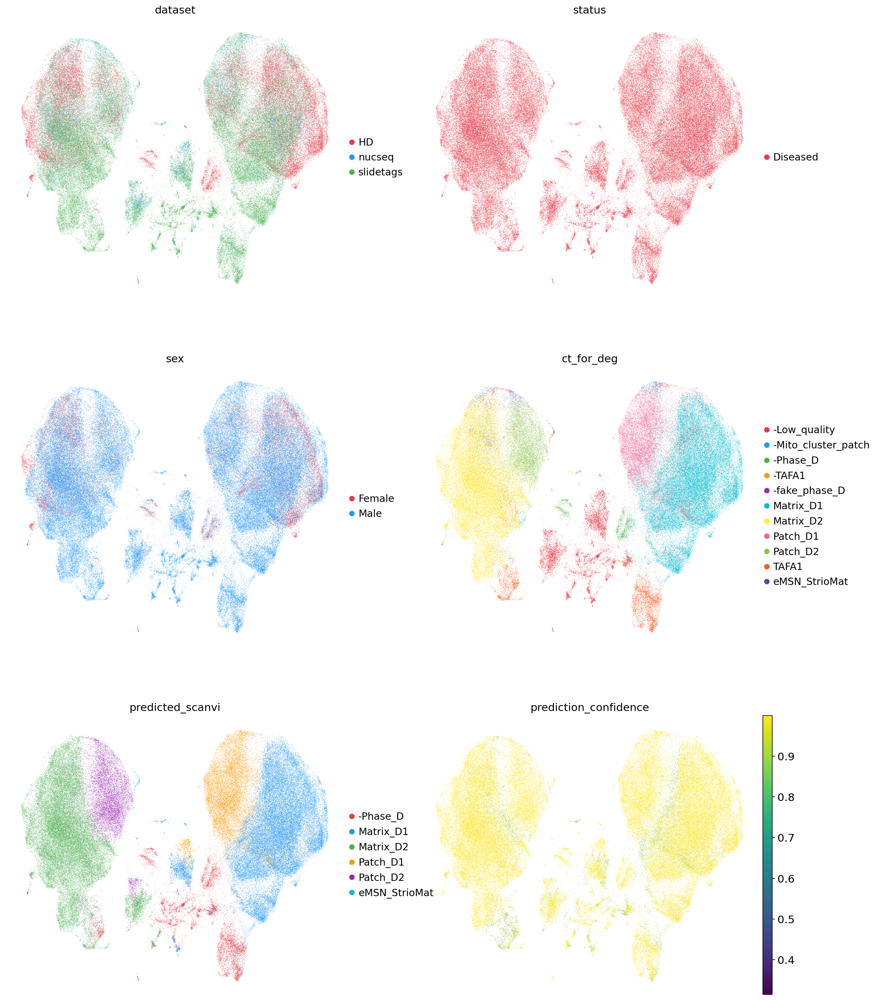

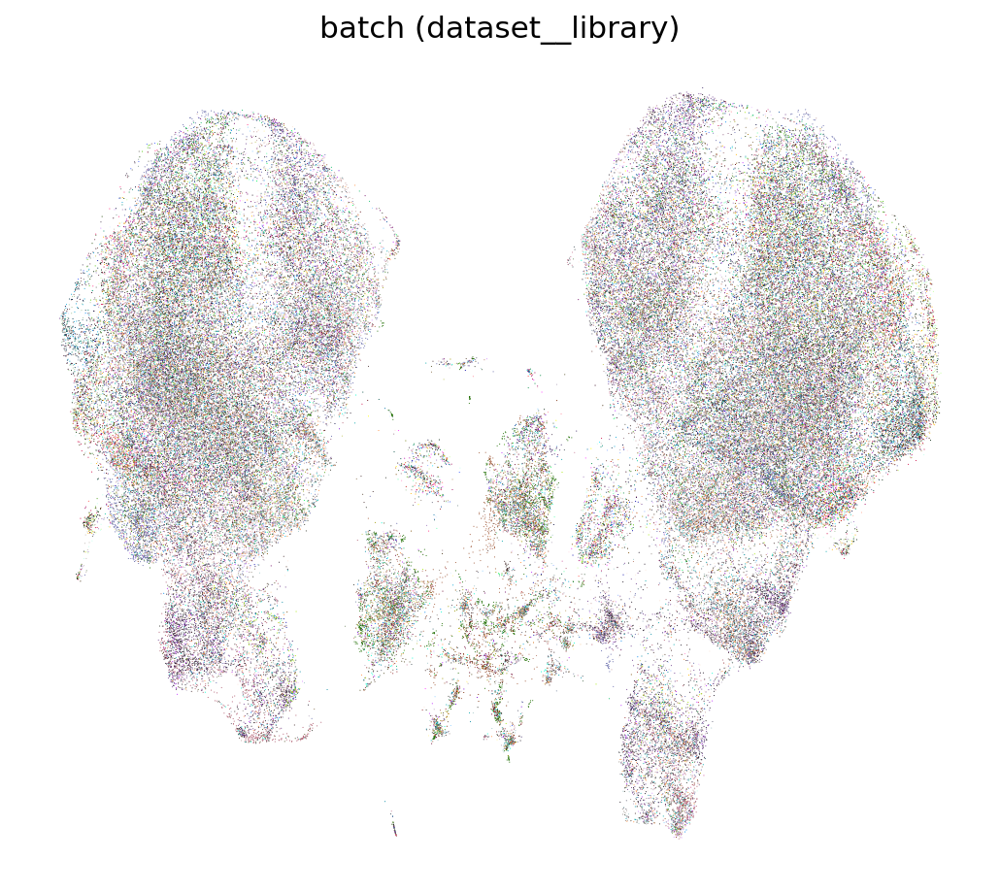

In [18]:
sc.settings.set_figure_params(figsize=(8, 7))
color = ["dataset", "status", "sex", TRAIN_LABEL_COL] + (["predicted_scanvi", "prediction_confidence"] if USE_SCANVI else [])
sc.pl.umap(adata, color=color, ncols=2, frameon=False, palette=lmu.custom_palette)
sc.pl.umap(adata, color="batch", frameon=False, legend_loc=None, title="batch (dataset__library)")

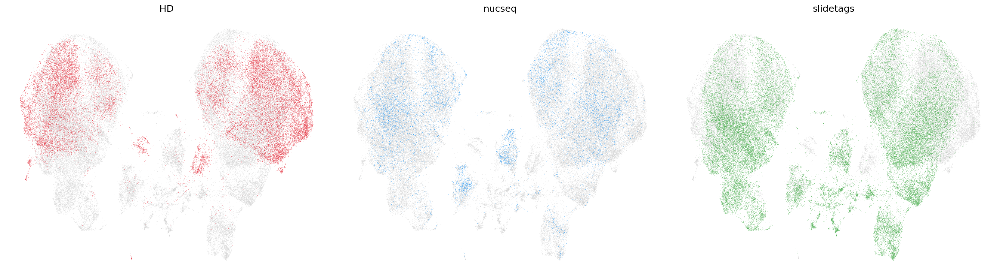

In [19]:
# each dataset on its own, on the shared embedding: good mixing = each dataset covers the same territory
fig, axes = plt.subplots(1, adata.obs["dataset"].nunique(), figsize=(7 * adata.obs["dataset"].nunique(), 6))
for ax, name in zip(axes, adata.obs["dataset"].cat.categories):
    sc.pl.umap(adata, color="dataset", groups=[name], ax=ax, show=False, frameon=False, title=name, legend_loc=None)
plt.tight_layout(); plt.show()

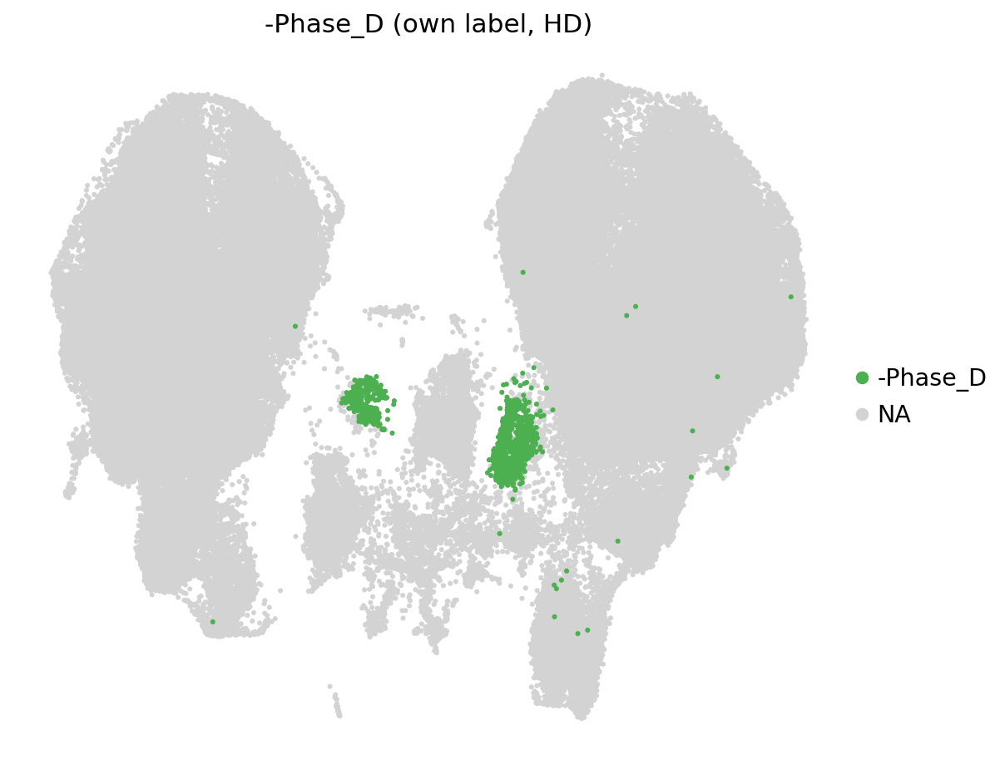

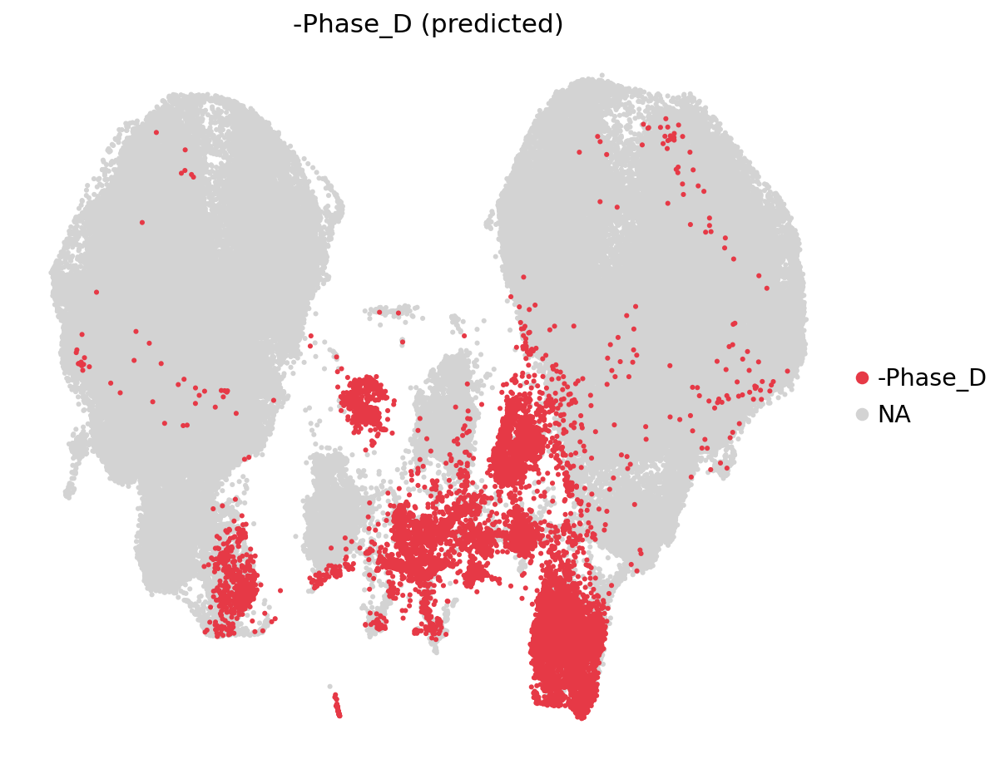

dataset              HD  nucseq  slidetags
predicted_scanvi                          
False             43115   15052      65794
True               2109     465       6854


In [20]:
sc.pl.umap(adata, color=TRAIN_LABEL_COL, groups=["-Phase_D"], frameon=False, title="-Phase_D (own label, HD)", palette=lmu.custom_palette, size=30)
if USE_SCANVI:
    sc.pl.umap(adata, color="predicted_scanvi", groups=["-Phase_D"], frameon=False, title="-Phase_D (predicted)", palette=lmu.custom_palette, size=30)
    print(pd.crosstab(adata.obs["predicted_scanvi"] == "-Phase_D", adata.obs["dataset"]))

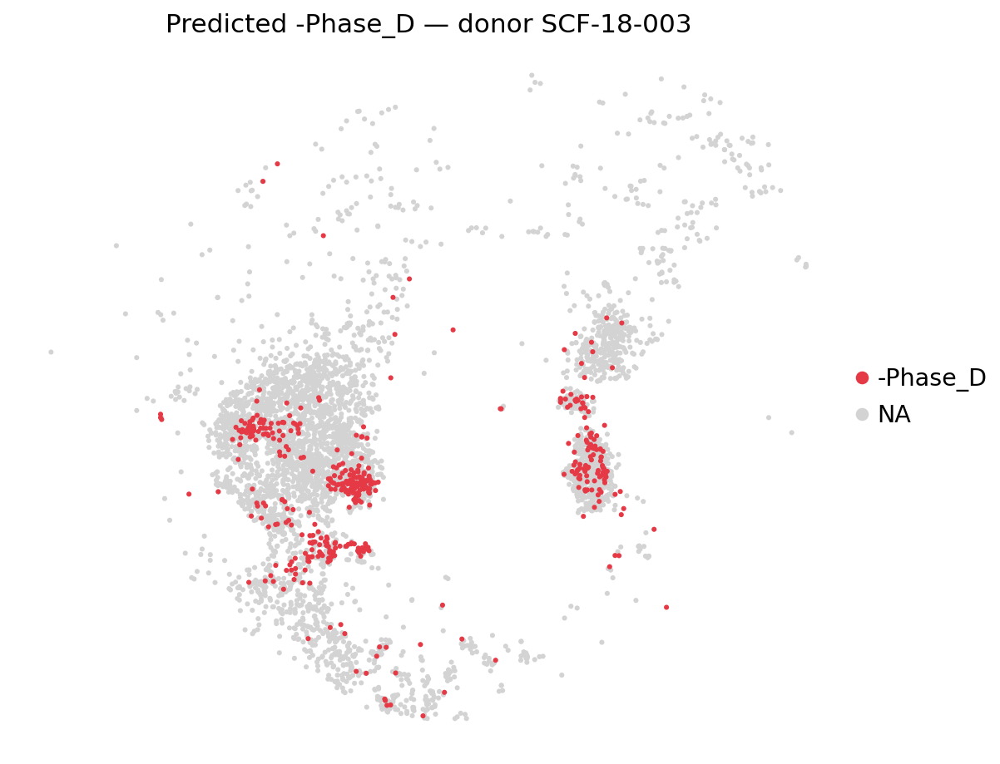

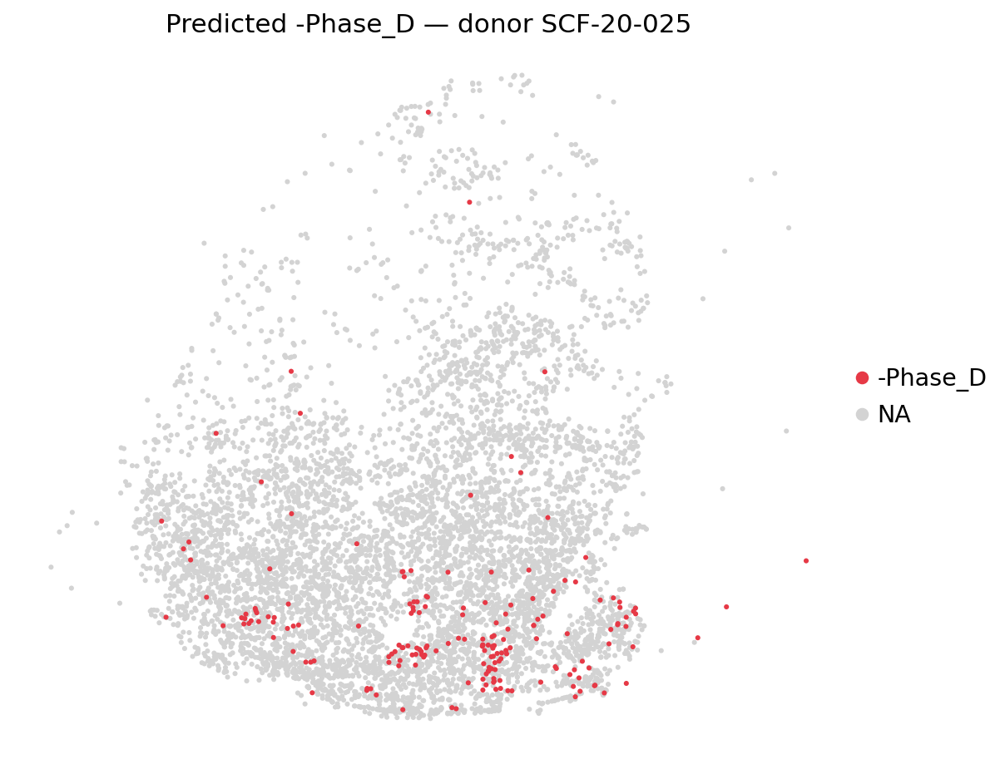

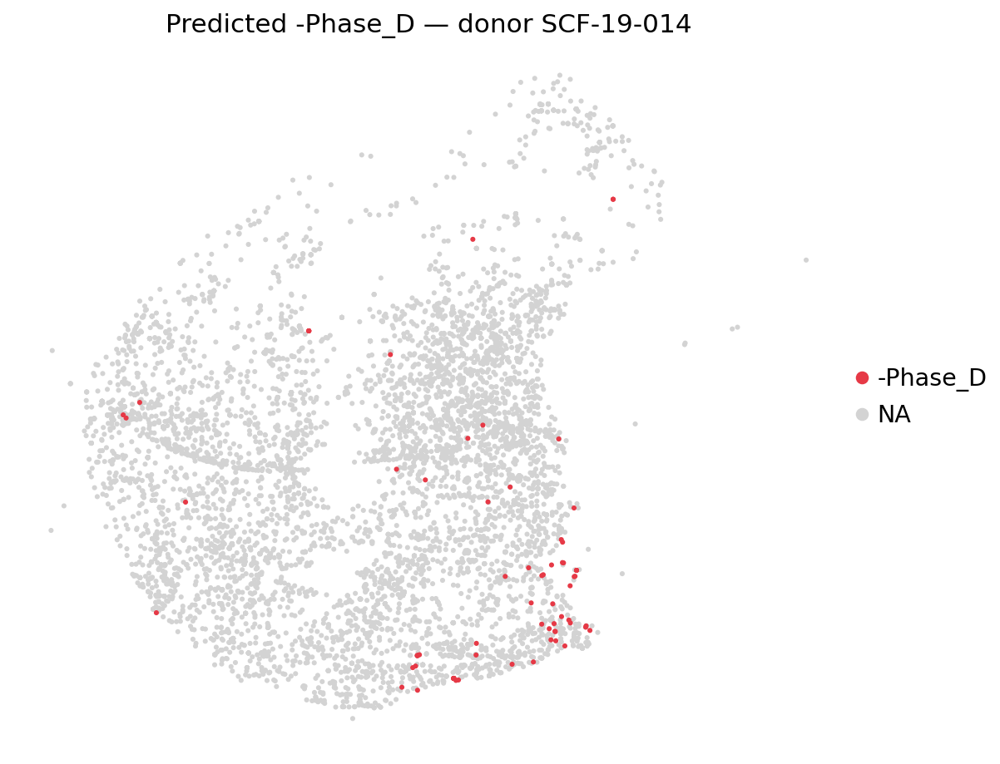

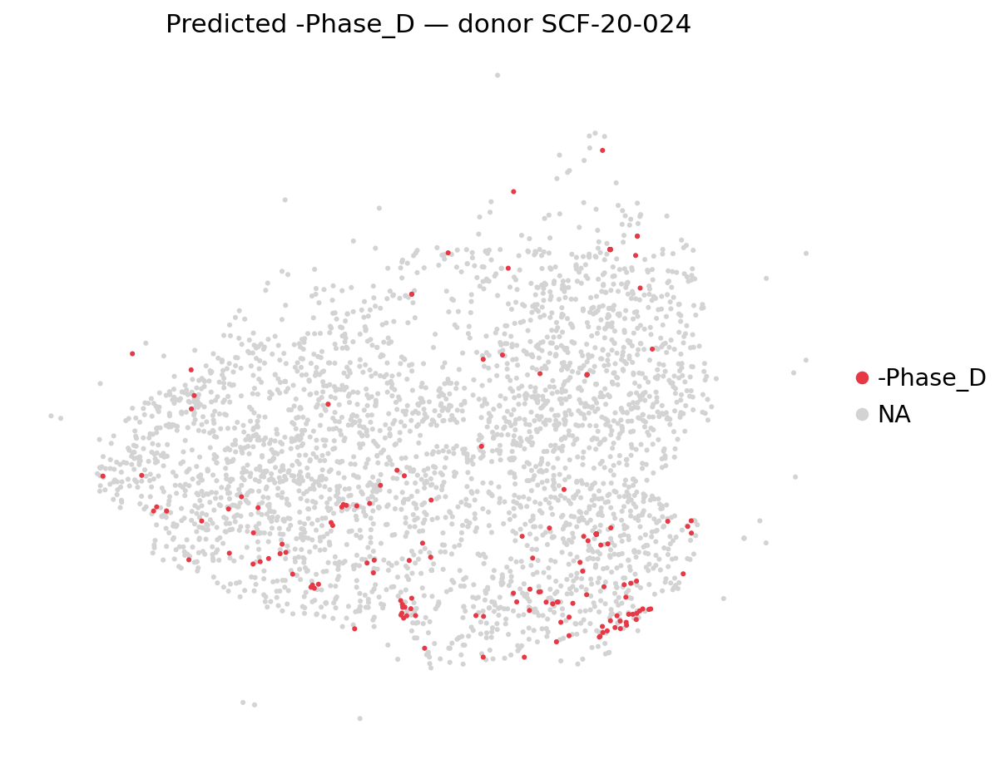

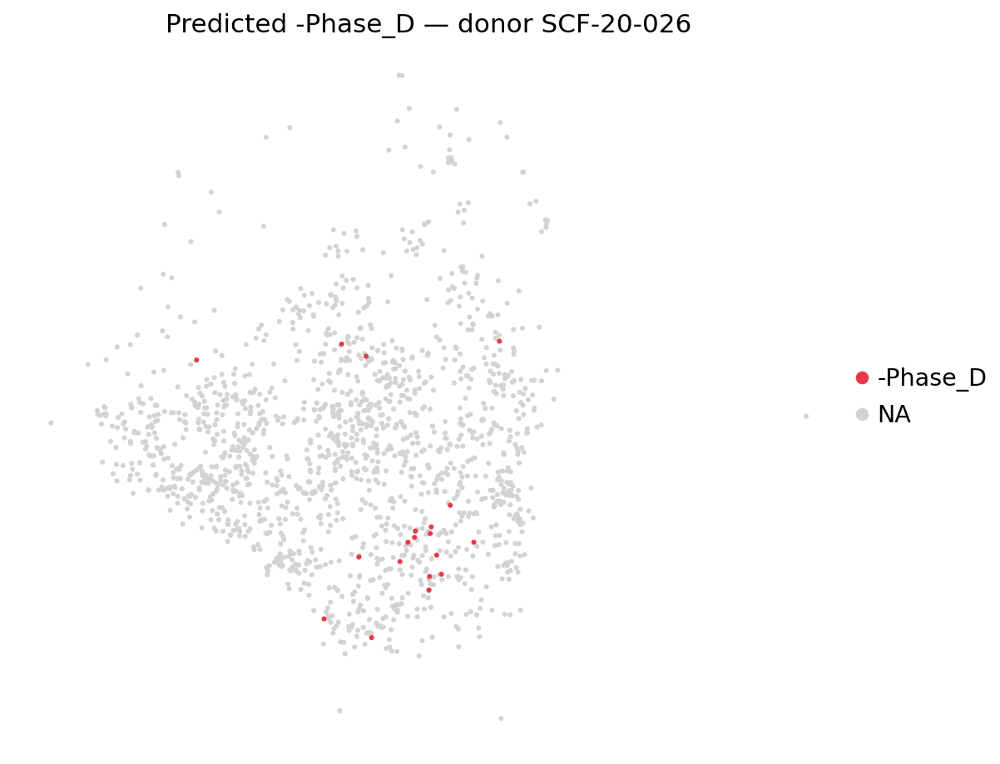

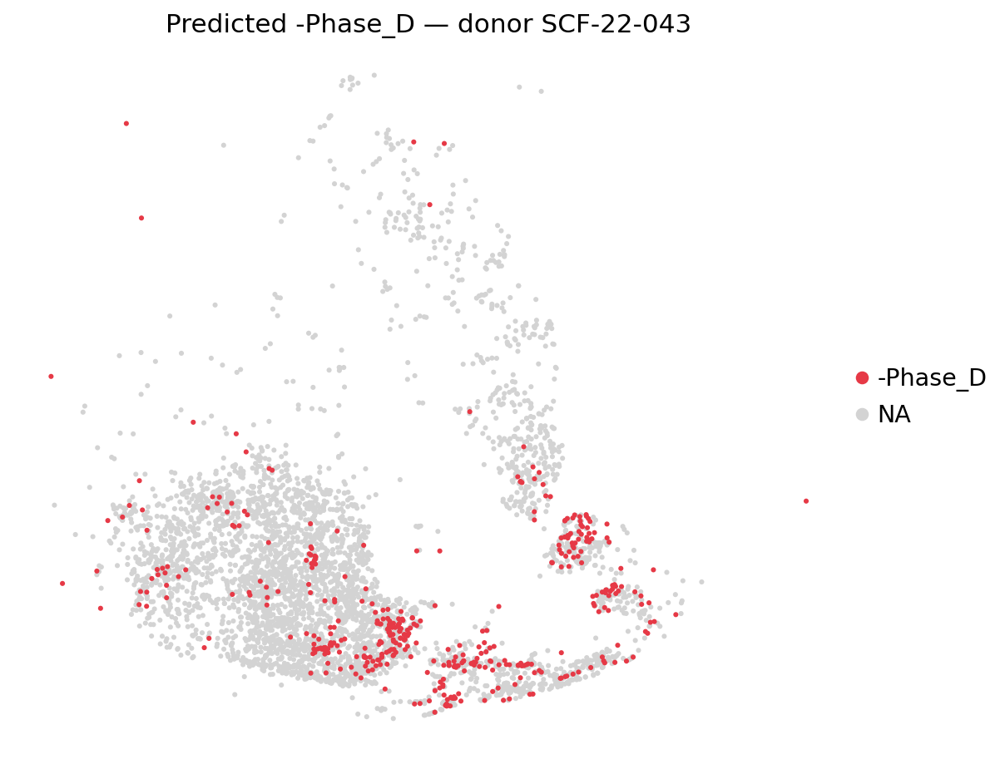

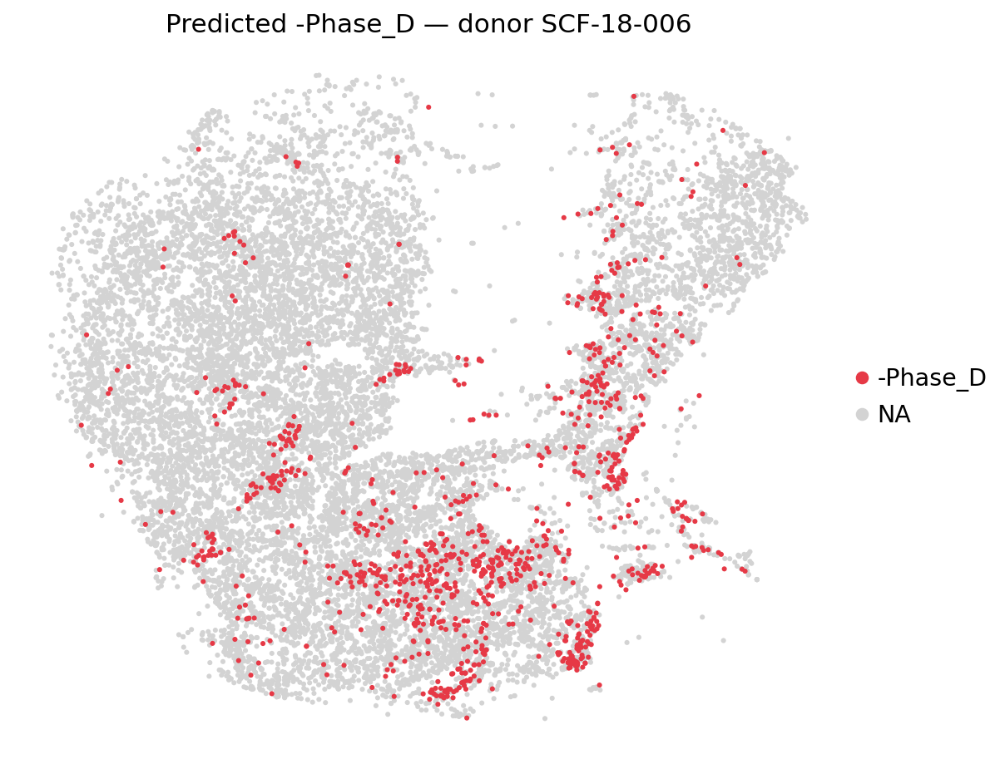

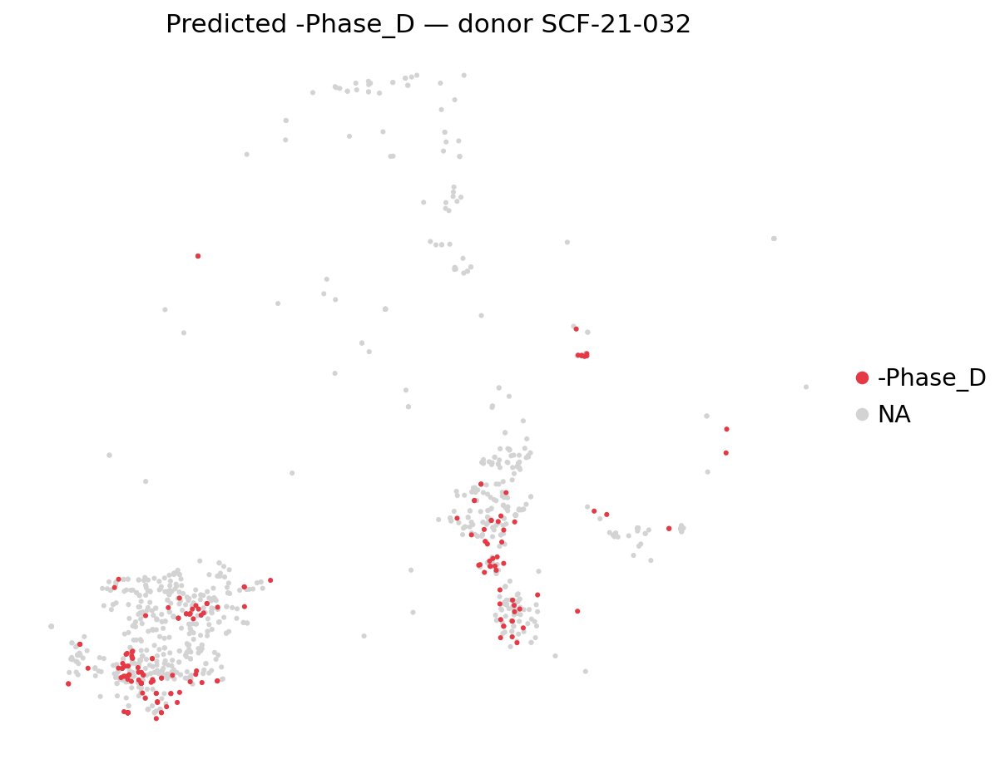

In [21]:
# SlideTags: predicted labels in aligned tissue coordinates, per donor
if USE_SCANVI:
    is_st = adata.obs["dataset"] == "slidetags"
    for d in adata.obs.loc[is_st, "donor_id_unified"].unique():
        tmp = adata[is_st & (adata.obs["donor_id_unified"] == d)].copy()
        tmp.obsm["spatial"] = tmp.obs[["spatial_x", "spatial_y"]].to_numpy()
        sc.pl.embedding(tmp, basis="spatial", color="predicted_scanvi", groups=["-Phase_D"], frameon=False,
                        title=f"Predicted -Phase_D — donor {d}", palette=lmu.custom_palette, size=30)

... storing 'highlight_shared_donor' as categorical


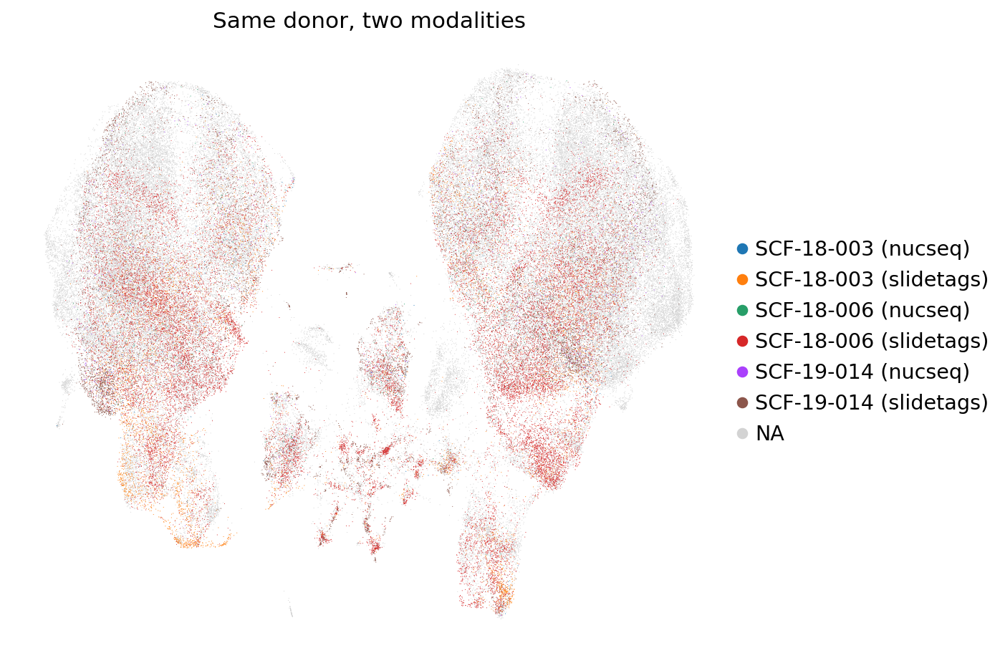

In [22]:
# Donor harmonization sanity check (Section 4): the same donor's cells from NucSeq and SlideTags should overlap
example_shared_donors = sorted(shared_nucseq_slidetags)[:3]
adata.obs["highlight_shared_donor"] = np.where(
    adata.obs["donor_id_unified"].isin(example_shared_donors),
    adata.obs["donor_id_unified"].astype(str) + " (" + adata.obs["dataset"].astype(str) + ")",
    "other",
)
sc.pl.umap(
    adata, color="highlight_shared_donor",
    groups=[d for d in adata.obs["highlight_shared_donor"].unique() if d != "other"],
    frameon=False, title="Same donor, two modalities",
)

## 9 · Comparison: Harmony on the same cells

Same cells and genes (`adatas`), integrated with Harmony on PCA instead of scVI. HVGs per `dataset` (as above), Harmony corrects the same technical unit as scVI (`batch`), not donor or sex: Harmony re-centres every level of `vars_use` with no way for biology to push back, and sex is heavily confounded with cohort here (XDP is X-linked, so ~all male; HD is balanced).

Seed set to 42
/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-10-30 14:47:29,001 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-30 14:47:29 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-30 14:47:29,003 - harmonypy - INFO -   Parameters:
2026-10-30 14:47:29 | [INFO]   Parameters:
2026-10-30 14:47:29,004 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-30 14:47:29 | [INFO]     max_iter_harmony: 30
2026-10-30 14:47:29,004 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-30 14:47:29 | [INFO]     max_iter_kmeans: 20
2026-10-30 14:47:29,005 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-30 14:47:29 | [INFO]     epsilon_cluster: 1e-05
2026-10-30 14:47:29,006 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-30 14:47:29 | [INFO]     epsilon_harmony: 0.0001
2026-10-30 14:47:29,007 - harmonypy - INFO -     ncl

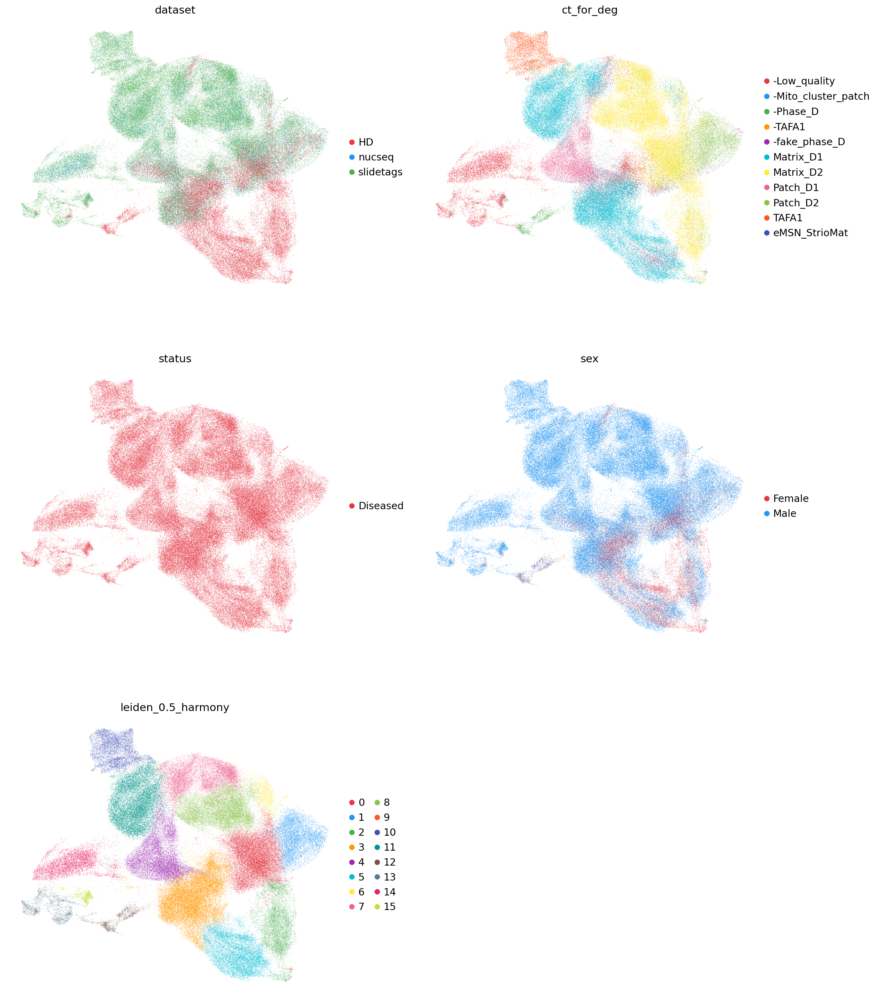

In [23]:
def run_harmony_integration(adata, hvg_batch_key, harmony_vars_use, n_top_genes=N_TOP_GENES,
                            n_pcs=50, max_iter_harmony=30, resolutions=[0.1, 0.3, 0.5], seed=42):
    # same steps as lmu.preprocess_common_pipeline(..., integrate_with_harmony=True), but with the HVG
    # batch_key (single column) decoupled from Harmony's vars_use (may be a list of columns)
    import harmonypy
    lmu.set_global_seeds(seed)

    adata.X = adata.layers["counts"].copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.layers["log1p_norm"] = adata.X.copy()

    sc.pp.highly_variable_genes(adata, n_top_genes=n_top_genes, flavor="seurat_v3", layer="counts", batch_key=hvg_batch_key)

    adata_hvg = adata[:, adata.var["highly_variable"]].copy()
    sc.pp.scale(adata_hvg, max_value=10)
    sc.tl.pca(adata_hvg, svd_solver="randomized", n_comps=n_pcs, random_state=seed)
    adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
    adata.uns["pca"] = adata_hvg.uns["pca"]
    del adata_hvg

    ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, vars_use=harmony_vars_use, max_iter_harmony=max_iter_harmony)
    Z = ho.Z_corr
    adata.obsm["X_pca_harmony"] = Z.T if Z.shape[0] != adata.n_obs else Z

    sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_pcs=n_pcs, random_state=seed)
    sc.tl.umap(adata, random_state=seed)
    for r in resolutions:
        sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}_harmony", flavor="igraph", n_iterations=2, random_state=seed)

    adata.X = adata.layers["counts"].copy()  # raw counts back in X
    return adata


adata_harmony = anndata.concat(adatas, join="inner", index_unique="-", merge="first")
adata_harmony = run_harmony_integration(adata_harmony, hvg_batch_key="dataset", harmony_vars_use=["batch"])

sc.pl.umap(adata_harmony, color=["dataset", TRAIN_LABEL_COL, "status", "sex", "leiden_0.5_harmony"],
           ncols=2, frameon=False, palette=lmu.custom_palette)

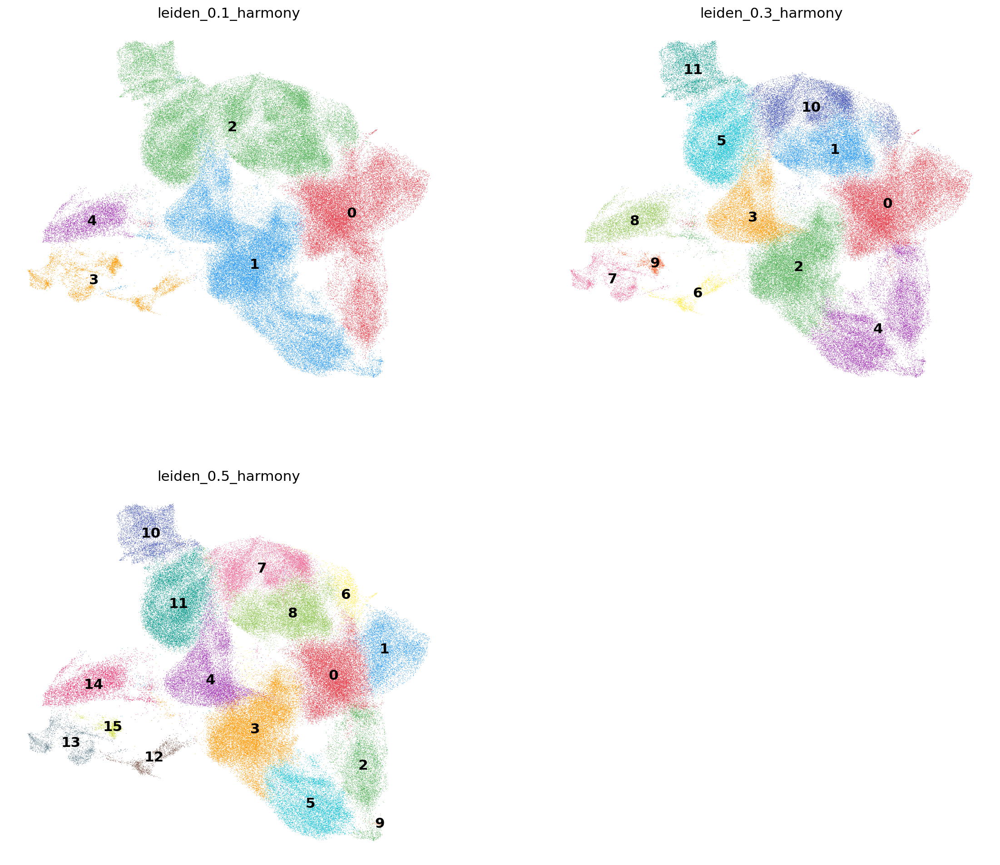

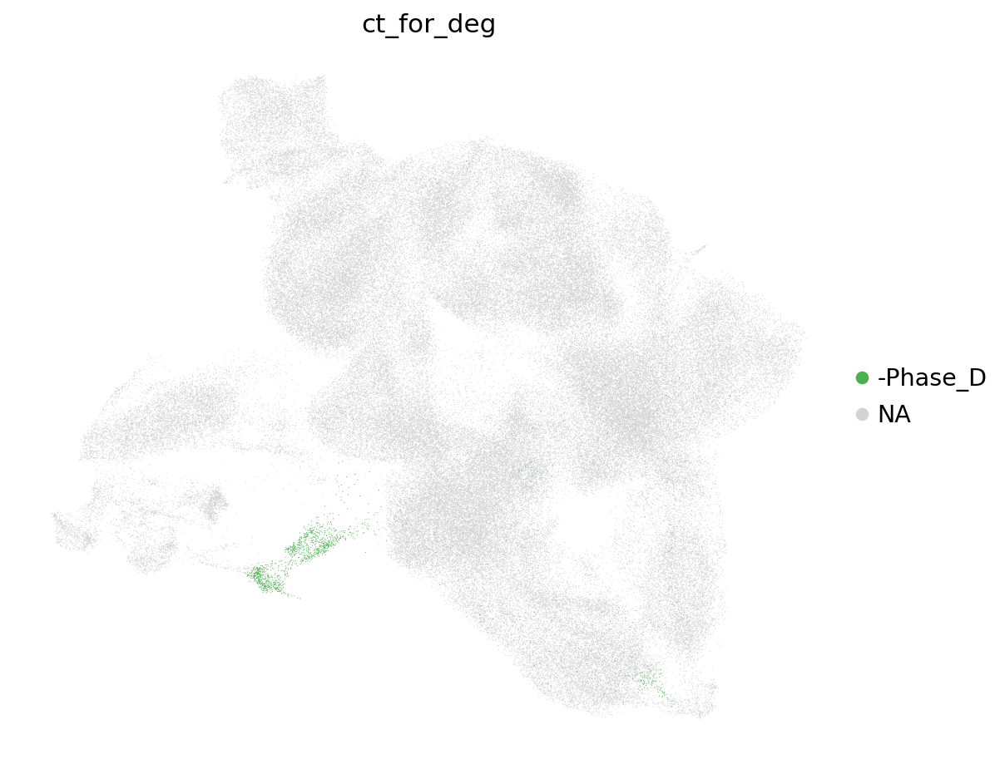

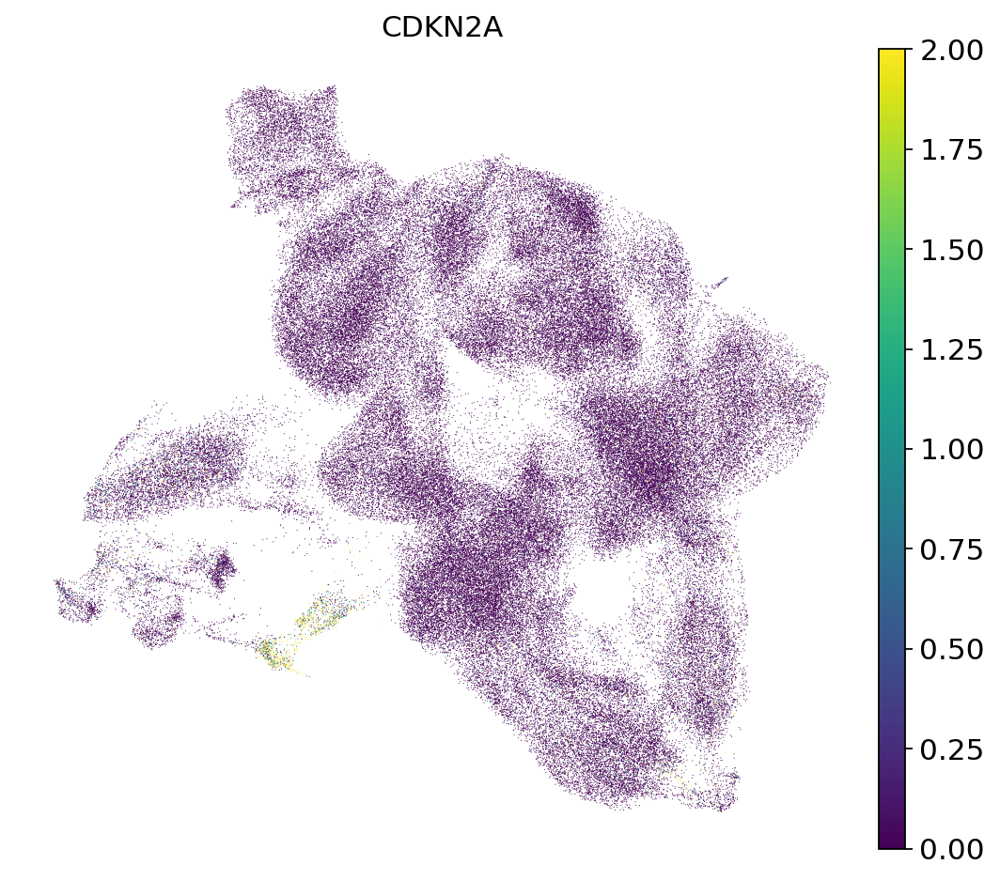

In [24]:
sc.pl.umap(adata_harmony, color=["leiden_0.1_harmony", "leiden_0.3_harmony", "leiden_0.5_harmony"],
           ncols=2, frameon=False, palette=lmu.custom_palette, legend_loc="on data")
sc.pl.umap(adata_harmony, color=TRAIN_LABEL_COL, groups=["-Phase_D"], frameon=False, palette=lmu.custom_palette)
sc.pl.umap(adata_harmony, color=["ENSG00000147889"], frameon=False, vmax=2, title="CDKN2A")

In [25]:
# Wilcoxon markers for chosen Harmony clusters (cluster ids change between runs -- set them after looking at the UMAP)
from utils import preprocessing

res = preprocessing.rank_markers_per_cluster(adata_harmony, "leiden_0.5_harmony", layer="log1p_norm", n_genes=50, markers=None,
                                             groups=["10", "8", "9"])
for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    display(df.merge(adata_harmony.var[["gene_symbol"]], left_on="names", right_index=True, how="left").head(30))

2026-10-30 14:51:08 | [INFO] cffi mode is CFFI_MODE.ANY
2026-10-30 14:51:08 | [INFO] R home found: /usr/lib/R
2026-10-30 14:51:08 | [INFO] R library path: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-10-30 14:51:08 | [INFO] LD_LIBRARY_PATH: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-10-30 14:51:08 | [INFO] Default options to initialize R: rpy2, --quiet, --no-save
2026-10-30 14:51:08 | [INFO] Environment variable "LD_LIBRARY_PATH" redefined by R and overriding existing variable. Current: "/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64", R: "/usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda

Cluster 10:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000204442,120.402199,3.656345,0.0,0.0,FAM155A
1,ENSG00000183662,116.660103,6.824163,0.0,0.0,FAM19A1
2,ENSG00000157542,115.428719,5.688155,0.0,0.0,KCNJ6
3,ENSG00000188641,112.171143,1.971632,0.0,0.0,DPYD
4,ENSG00000198947,110.007004,2.450319,0.0,0.0,DMD
5,ENSG00000133083,109.532722,1.596539,0.0,0.0,DCLK1
6,ENSG00000179915,109.140717,1.551294,0.0,0.0,NRXN1
7,ENSG00000145242,107.754379,3.959233,0.0,0.0,EPHA5
8,ENSG00000124225,107.679901,2.769425,0.0,0.0,PMEPA1
9,ENSG00000121989,107.421310,2.561131,0.0,0.0,ACVR2A


Cluster 8:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000156687,121.542061,1.635255,0.0,0.0,UNC5D
1,ENSG00000140090,118.017097,1.925545,0.0,0.0,SLC24A4
2,ENSG00000146360,113.645622,2.040236,0.0,0.0,GPR6
3,ENSG00000181195,106.655090,1.743942,0.0,0.0,PENK
4,ENSG00000149295,104.277580,1.783420,0.0,0.0,DRD2
5,ENSG00000231533,101.280815,1.628778,0.0,0.0,AL078601.2
6,ENSG00000224577,100.086502,1.616550,0.0,0.0,LINC01117
7,ENSG00000173482,97.485458,1.430638,0.0,0.0,PTPRM
8,ENSG00000203737,96.641472,2.133175,0.0,0.0,GPR52
9,ENSG00000137766,95.926598,1.660062,0.0,0.0,UNC13C


Cluster 9:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000044115,13.119240,3.987412,2.554853e-39,5.528380e-35,CTNNA1
1,ENSG00000227906,13.092916,4.503815,3.614619e-39,5.528380e-35,SNAP25-AS1
2,ENSG00000258663,13.039131,5.251015,7.328712e-39,7.472599e-35,AL117190.2
3,ENSG00000233635,12.977458,4.443851,1.642408e-38,1.180953e-34,AC015923.1
4,ENSG00000121957,12.965077,4.683365,1.930356e-38,1.180953e-34,GPSM2
5,ENSG00000138735,12.950045,4.548669,2.348179e-38,1.197141e-34,PDE5A
6,ENSG00000259589,12.918444,4.708273,3.542329e-38,1.470491e-34,AC073167.1
7,ENSG00000257647,12.912117,5.037800,3.845805e-38,1.470491e-34,AC124312.2
8,ENSG00000254733,12.893510,4.233663,4.896374e-38,1.574410e-34,AP001831.1
9,ENSG00000237919,12.889661,4.906687,5.146980e-38,1.574410e-34,AL158840.1
